# Exercise 23 — Student Performance Analysis
 Exercise 23 — Student Performance Analysis
- upload the student file and answer the questions: average score, highest/lowest score, top student, course counts, average score by course. Then create a bar chart of average score by course, a histogram of scores, and a bar chart of students by course.
- clean → transform → calculate performance → group → analyze → visualize.
clean → transform → calculate performance → group → analyze → visualize

*Note: "course" = the `Program` column, "score" = `Overall_Score`.*

## 1. Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("Student_Performance_Analysis_Complex.xlsx")
print("Raw shape:", df.shape)
df.head()

Raw shape: (230, 19)


,Student_ID,Student_Name,Gender,Age,County,Program,Learning_Mode,Internet_Access,Study_Hours_Per_Week,Attendance_Percentage,Previous_GPA,Assignment_Score,Quiz_Score,Midterm_Score,Final_Exam_Score,Participation_Score,Overall_Score,Performance_Level,Pass_Status
0,ST1001,Oscar Kamau,Male,33,Uasin Gishu,Business Intelligence,Online,Reliable,5.3,93.6,2.78,50.5,51.0,94.4,64.1,63.8,67.0,Average,Pass
1,ST1002,David Kariuki,Female,29,Nairobi,Software Engineering,Physical,Reliable,15.4,77.1,2.46,53.4,100.0,100.0,100.0,56.8,86.4,Excellent,Pass
2,ST1003,Ian Wambui,Female,32,Kisumu,DataScience,Online,Reliable,6.1,75.0,3.08,35.4,51.2,75.8,100.0,47.7,68.5,Average,Pass
3,ST1004,George Maina,Female,28,Nairobi,Business Intelligence,Hybrid,Sometimes unreliable,12.7,67.6,2.93,48.5,66.9,82.9,66.3,58.3,66.2,Average,Pass
4,ST1005,Mark Mutua,Female,27,Machakos,Data Science,Online,Reliable,8.2,67.9,3.53,30.0,65.3,72.1,76.8,49.4,61.8,Average,Pass


## 2. Inspect the data (find what needs cleaning)

In [2]:
df.info()
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
for col in ["Gender", "County", "Program"]:
    print(df[col].value_counts(), "\n")

<class 'pandas.DataFrame'>
RangeIndex: 230 entries, 0 to 229
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             230 non-null    str    
 1   Student_Name           230 non-null    str    
 2   Gender                 230 non-null    str    
 3   Age                    230 non-null    int64  
 4   County                 230 non-null    str    
 5   Program                230 non-null    str    
 6   Learning_Mode          230 non-null    str    
 7   Internet_Access        226 non-null    str    
 8   Study_Hours_Per_Week   224 non-null    float64
 9   Attendance_Percentage  225 non-null    float64
 10  Previous_GPA           225 non-null    float64
 11  Assignment_Score       230 non-null    float64
 12  Quiz_Score             225 non-null    float64
 13  Midterm_Score          230 non-null    float64
 14  Final_Exam_Score       230 non-null    float64
 15  Participation_Sco

## 3. Clean

In [3]:
# remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# fix inconsistent text (extra spaces, upper/lower case)
for col in ["Gender", "County", "Program", "Learning_Mode", "Internet_Access"]:
    df[col] = df[col].str.strip()
df["Gender"] = df["Gender"].str.title()
df["County"] = df["County"].str.title()

# "DataScience", "data science", "Software engineering" -> one consistent name
df["Program"] = df["Program"].str.title().replace({"Datascience": "Data Science"})

In [4]:
# handle missing values
df["Internet_Access"] = df["Internet_Access"].fillna("Unknown")
num_cols = ["Study_Hours_Per_Week", "Attendance_Percentage", "Previous_GPA",
            "Quiz_Score", "Participation_Score"]
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

print("Clean shape:", df.shape)
print(df.isna().sum().sum(), "missing values left")
print(df["Program"].value_counts())

Clean shape: (225, 19)
0 missing values left
Program
Software Engineering     62
Cyber Security           62
Data Science             58
Business Intelligence    43
Name: count, dtype: int64


## 4. Calculate performance

In [5]:
avg_score = df["Overall_Score"].mean()
highest = df["Overall_Score"].max()
lowest = df["Overall_Score"].min()
top_student = df.loc[df["Overall_Score"].idxmax(), ["Student_ID", "Student_Name", "Program", "Overall_Score"]]

print(f"Average score: {avg_score:.2f}")
print(f"Highest score: {highest}")
print(f"Lowest score:  {lowest}")
print("\nTop student:\n", top_student.to_string())

Average score: 73.56
Highest score: 91.1
Lowest score:  42.4

Top student:
 Student_ID             ST1180
Student_Name       Rose Mutua
Program          Data Science
Overall_Score            91.1


## 5. Group and analyze

In [6]:
course_counts = df["Program"].value_counts()
avg_by_course = df.groupby("Program")["Overall_Score"].mean().round(2).sort_values(ascending=False)

print("Students per course:\n", course_counts)
print("\nAverage score by course:\n", avg_by_course)

Students per course:
 Program
Software Engineering     62
Cyber Security           62
Data Science             58
Business Intelligence    43
Name: count, dtype: int64

Average score by course:
 Program
Data Science             74.55
Software Engineering     73.89
Cyber Security           73.48
Business Intelligence    71.85
Name: Overall_Score, dtype: float64


## 6. Visualize

**Bar chart: average score by course**

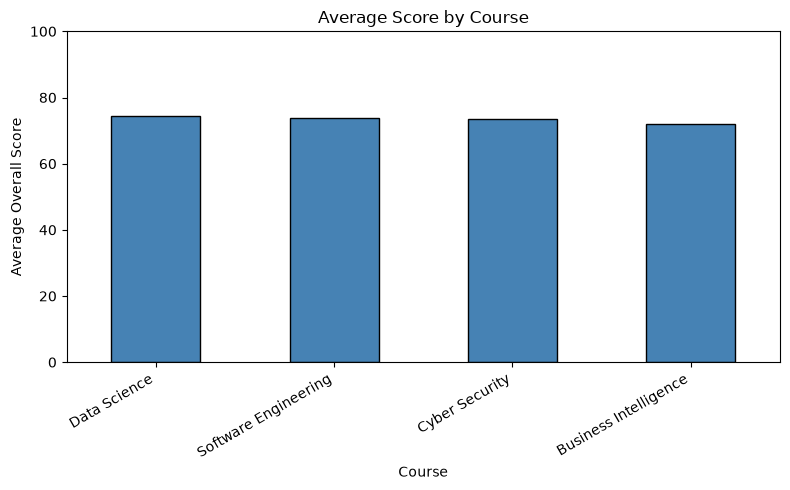

In [7]:
plt.figure(figsize=(8, 5))
avg_by_course.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Average Score by Course")
plt.xlabel("Course")
plt.ylabel("Average Overall Score")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

**Histogram of scores**

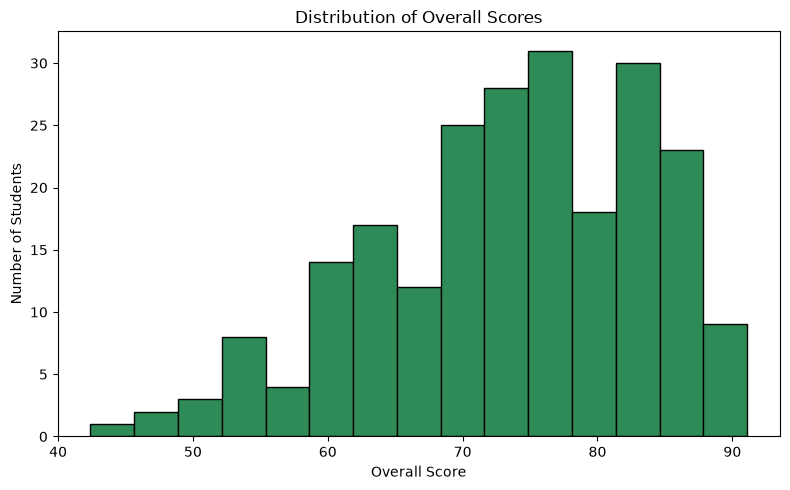

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(df["Overall_Score"], bins=15, color="seagreen", edgecolor="black")
plt.title("Distribution of Overall Scores")
plt.xlabel("Overall Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

**Bar chart: number of students by course**

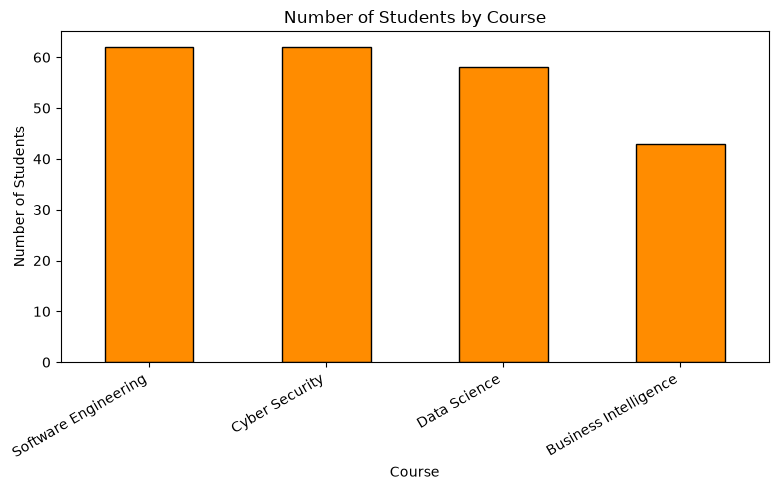

In [9]:
plt.figure(figsize=(8, 5))
course_counts.plot(kind="bar", color="darkorange", edgecolor="black")
plt.title("Number of Students by Course")
plt.xlabel("Course")
plt.ylabel("Number of Students")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()